In [4]:
import pandas as pd
import numpy as np

# Semente fixa solicitada no projeto
np.random.seed(42)

# 1. Carrega o dataset sem o aviso de Dtype
df = pd.read_csv('../dados/auto_infracao_2021.csv', sep=';', encoding='latin1', low_memory=False)

# 2. Seleciona as colunas necessárias
colunas_chave = [
    'UF',                     # Estado
    'DS_BIOMAS_ATINGIDOS',    # Bioma
    'TP_PESSOA_INFRATOR',     # PF ou PJ
    'QT_AREA',                # Área afetada em hectares
    'VAL_AUTO_INFRACAO'       # Valor da multa
]

df_modelo = df[colunas_chave].dropna().copy()

# 3. Converte os valores numéricos de texto/vírgula para float
for col in ['VAL_AUTO_INFRACAO', 'QT_AREA']:
    df_modelo[col] = (
        df_modelo[col]
        .astype(str)
        .str.replace('.', '', regex=False)   # Remove ponto de milhar
        .str.replace(',', '.', regex=False)   # Troca vírgula por ponto decimal
    )
    df_modelo[col] = pd.to_numeric(df_modelo[col], errors='coerce')

# Remove eventuais linhas que falharam na conversão numérica
df_modelo = df_modelo.dropna().copy()

# 4. Cria a Variável-Alvo Binária (y): Multa_Alta (1 = Alta, 0 = Baixa)
mediana_multa = df_modelo['VAL_AUTO_INFRACAO'].median()
df_modelo['Multa_Alta'] = (df_modelo['VAL_AUTO_INFRACAO'] > mediana_multa).astype(int)

# 5. Exibe o resumo do pré-processamento
print(f"Total de registros limpos: {len(df_modelo)}")
print(f"Valor mediano da multa para divisão: R$ {mediana_multa:,.2f}")
print("\nDistribuição das classes (0 = Baixa, 1 = Alta):")
print(df_modelo['Multa_Alta'].value_counts())
df_modelo.head()

Total de registros limpos: 54
Valor mediano da multa para divisão: R$ 96,500.00

Distribuição das classes (0 = Baixa, 1 = Alta):
Multa_Alta
0    27
1    27
Name: count, dtype: int64


,UF,DS_BIOMAS_ATINGIDOS,TP_PESSOA_INFRATOR,QT_AREA,VAL_AUTO_INFRACAO,Multa_Alta
0,AM,Amazonia,PF,19.000,95000.0,0
1308,PA,Amazonia,PF,26.213,135000.0,1
1350,GO,Cerrado,PF,17.260,36000.0,0
1359,GO,Cerrado,PF,39.180,80000.0,0
1456,RS,Pampa,PF,2.320,69000.0,0


Matplotlib is building the font cache; this may take a moment.


Total de registros utilizados: 9620
Acurácia no conjunto de teste: 66.56%

Relatório de Classificação:
              precision    recall  f1-score   support

 Multa Baixa       0.72      0.55      0.62      1447
  Multa Alta       0.63      0.78      0.70      1439

    accuracy                           0.67      2886
   macro avg       0.68      0.67      0.66      2886
weighted avg       0.68      0.67      0.66      2886



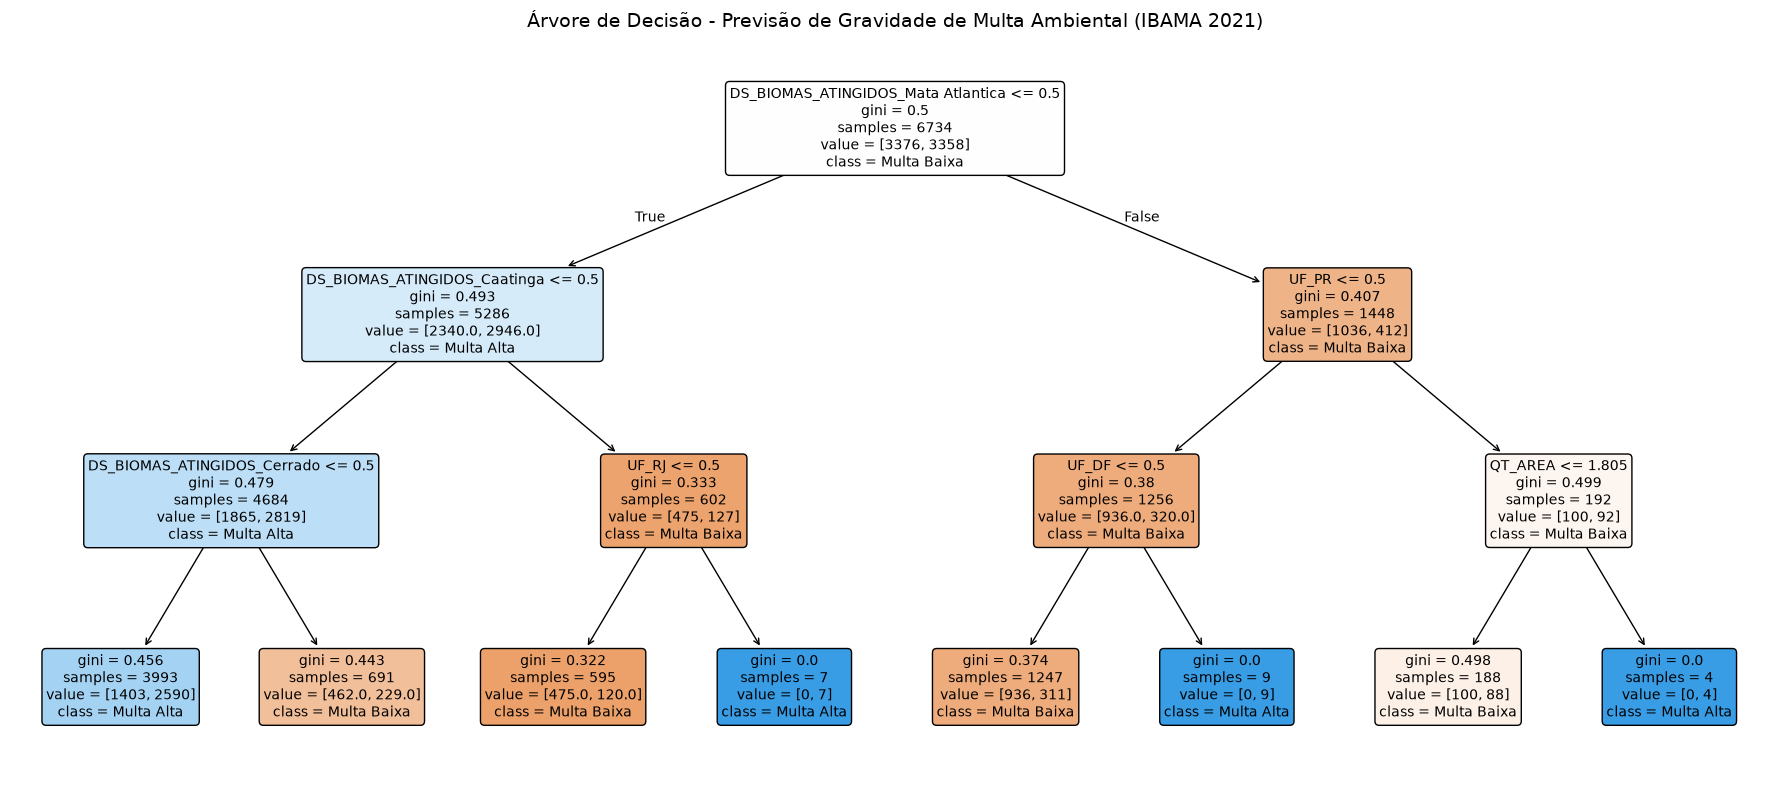

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score

# 1. Reamostragem com tratamento de nulos para expandir o dataset
df = pd.read_csv('../dados/auto_infracao_2021.csv', sep=';', encoding='latin1', low_memory=False)

colunas = ['UF', 'DS_BIOMAS_ATINGIDOS', 'TP_PESSOA_INFRATOR', 'QT_AREA', 'VAL_AUTO_INFRACAO']
df_prep = df[colunas].copy()

# Trata textos ausentes
df_prep['DS_BIOMAS_ATINGIDOS'] = df_prep['DS_BIOMAS_ATINGIDOS'].fillna('Não informado')
df_prep['TP_PESSOA_INFRATOR'] = df_prep['TP_PESSOA_INFRATOR'].fillna('Outros')
df_prep['UF'] = df_prep['UF'].fillna('Outro')

# Trata numéricos
for col in ['VAL_AUTO_INFRACAO', 'QT_AREA']:
    df_prep[col] = (
        df_prep[col].astype(str)
        .str.replace('.', '', regex=False)
        .str.replace(',', '.', regex=False)
    )
    df_prep[col] = pd.to_numeric(df_prep[col], errors='coerce')

df_prep['QT_AREA'] = df_prep['QT_AREA'].fillna(0)
df_prep = df_prep.dropna(subset=['VAL_AUTO_INFRACAO']).copy()

# Criação do target (y)
mediana = df_prep['VAL_AUTO_INFRACAO'].median()
df_prep['Multa_Alta'] = (df_prep['VAL_AUTO_INFRACAO'] > mediana).astype(int)

# 2. Definição de X e y + One-Hot Encoding
X = df_prep[['UF', 'DS_BIOMAS_ATINGIDOS', 'TP_PESSOA_INFRATOR', 'QT_AREA']]
X = pd.get_dummies(X, drop_first=True)
y = df_prep['Multa_Alta']

# 3. Divisão em Treino (70%) e Teste (30%) com semente fixa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 4. Treinamento da Árvore de Decisão (profundidade 3 para ser legível)
modelo_arvore = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
modelo_arvore.fit(X_train, y_train)

# 5. Avaliação do Modelo
y_pred = modelo_arvore.predict(X_test)
print(f"Total de registros utilizados: {len(df_prep)}")
print(f"Acurácia no conjunto de teste: {accuracy_score(y_test, y_pred):.2%}\n")
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Multa Baixa', 'Multa Alta']))

# 6. Plotagem visual da Árvore de Decisão
plt.figure(figsize=(18, 8))
plot_tree(
    modelo_arvore, 
    feature_names=X.columns.tolist(), 
    class_names=['Multa Baixa', 'Multa Alta'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão - Previsão de Gravidade de Multa Ambiental (IBAMA 2021)", fontsize=14)
plt.tight_layout()
plt.show()